# 1、Calculating cosine similarity

## Preparation

In [16]:
import json
import torch
import numpy as np
import pandas as pd
import matplotlib
# 弹出绘图窗口
# matplotlib.use('TkAgg')
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable

from model.CSU_EI import CSUEI
from model.tokenizer import build_tokenizer
from utils.data_preprocessing import pre_processing_ms, pre_processing_smi

## Loading the model

In [17]:
with open("configs/config.json", 'r') as f:
        config_json = json.loads(f.read())
model_dict = torch.load("model_weight/CSU_EI_weight/trained_model_6+6_16epoc+1024+3e4_2025-01-09_204745.pth", map_location=config_json["device"])
model = CSUEI(**config_json["model_config"])
model.load_state_dict(model_dict)
tokenizer = build_tokenizer(config_json['roberta_tokenizer_path'])
model.to(config_json["device"])

load pretrain smiles model


CSUEI(
  (Smiles_model): SmilesModel(
    (smiles_model): RobertaModel(
      (embeddings): RobertaEmbeddings(
        (word_embeddings): Embedding(181, 768, padding_idx=1)
        (position_embeddings): Embedding(505, 768, padding_idx=1)
        (token_type_embeddings): Embedding(1, 768)
        (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (encoder): RobertaEncoder(
        (layer): ModuleList(
          (0-5): 6 x RobertaLayer(
            (attention): RobertaAttention(
              (self): RobertaSelfAttention(
                (query): Linear(in_features=768, out_features=768, bias=True)
                (key): Linear(in_features=768, out_features=768, bias=True)
                (value): Linear(in_features=768, out_features=768, bias=True)
                (dropout): Dropout(p=0.1, inplace=False)
              )
              (output): RobertaSelfOutput(
                (dense): Linear(in_features=76

## Data Preprocessing

In [35]:
# Load data
with open("data/xianglansu/smiles_ms.json", 'r') as f:
# with open("data/set1/smiles_ms.json", 'r') as f:

    nist_23data = json.loads(f.read())

SMILES = []
EIMS = []
for data in nist_23data:
    EIMS.append(data["peaks"])
    SMILES.append(data["smiles"])

In [18]:
# read csv file UMAP
data = pd.read_csv("data/nist23_test/test.csv")


# get 100 smiles and ms data from nist23_test/test.csv randomly, set seed to 0
# data = data.sample(n=100, random_state=2)
# data = data.reset_index(drop=True)
SMILES = data["smiles"]
EIMS = data["peaks"]

In [19]:
smiles_ids_list = []
smiles_mask_list = []
for smiles in SMILES:
    smiles_ids, smiles_mask = pre_processing_smi(smiles,tokenizer,config_json)
    smiles_ids_list.append(smiles_ids)
    smiles_mask_list.append(smiles_mask)

smiles_ids = torch.cat(smiles_ids_list, dim=0).to(config_json["device"])
smiles_mask = torch.cat(smiles_mask_list, dim=0).to(config_json["device"])

In [20]:
mz_list = []
intensity_list = []
ms_mask_list = []
for eims in EIMS:
    mz, intensity, ms_mask = pre_processing_ms(eims,config_json)
    mz_list.append(mz)
    intensity_list.append(intensity)
    ms_mask_list.append(ms_mask)

mz = torch.cat(mz_list, dim=0).to(config_json["device"])
intensity = torch.cat(intensity_list, dim=0).to(config_json["device"])
ms_mask = torch.cat(ms_mask_list, dim=0).to(config_json["device"])

## Building features

In [21]:
batch_size = 100
test_smiles_feature = []
test_ms_feature = []
with torch.no_grad():
    for i in range(0, len(smiles_ids), batch_size):
        model.to(config_json["device"])
        model.eval()
        
        # 获取当前批次的数据
        smiles_feature, smiles_score = model.smiles_encoder([smiles_ids[i:i+batch_size], smiles_mask[i:i+batch_size]])
        ms_feature, ms_score = model.ms_encoder([mz[i:i+batch_size], intensity[i:i+batch_size], ms_mask[i:i+batch_size]])
        test_smiles_feature.append(smiles_feature)
        test_ms_feature.append(ms_feature)
test_smiles_feature = torch.cat(test_smiles_feature, dim=0)
test_ms_feature = torch.cat(test_ms_feature, dim=0)

# torch.save(test_smiles_feature, "data/nist23_test/test_smiles_feature.pth")
# torch.save(test_ms_feature, "data/nist23_test/test_ms_feature.pth")

## Calculating cosine similarity

In [64]:
test_smiles_feature /= torch.norm(test_smiles_feature, dim=-1, keepdim=True)
test_ms_feature /= torch.norm(test_ms_feature, dim=-1, keepdim=True)
similarity = test_smiles_feature.cpu().numpy() @ test_ms_feature.cpu().numpy().T

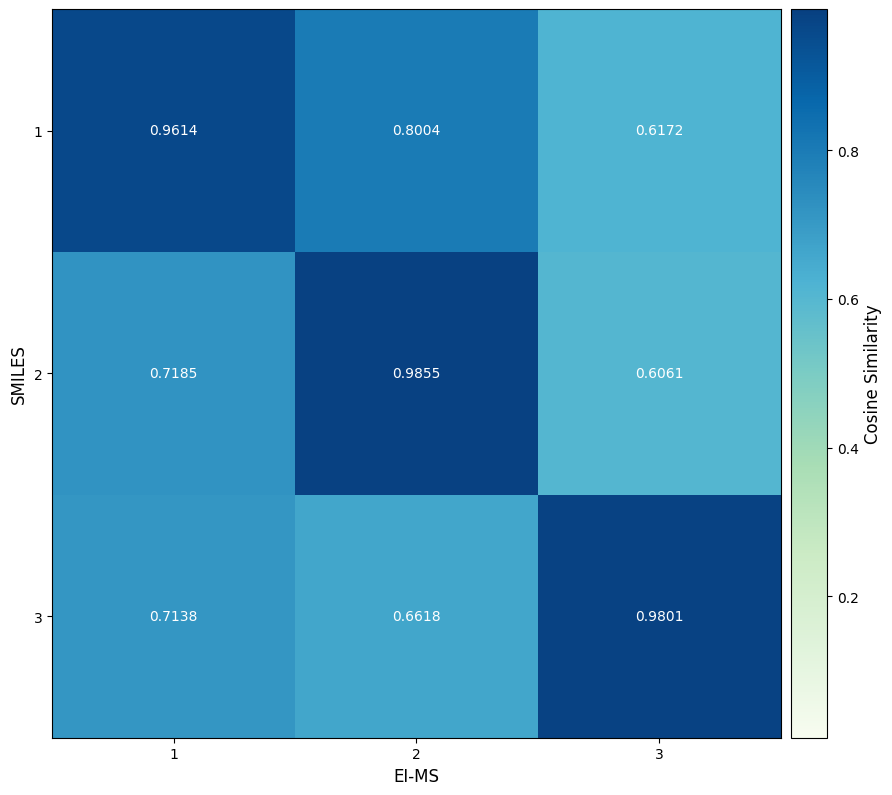

In [65]:
fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest')

norm = Normalize(vmin=0.01, vmax=0.99)
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest', norm=norm)

for i in range(similarity.shape[0]):
    for j in range(similarity.shape[1]):
        color = "white" if similarity[i, j] > 0.5 else "black"
        ax.text(j, i, np.round(similarity[i, j], 4), ha="center", va="center", color=color, fontsize=10)

ax.set_xticks(range(similarity.shape[1]))
ax.set_xticklabels(range(1, similarity.shape[1] + 1))
ax.set_yticks(range(similarity.shape[0]))
ax.set_yticklabels(range(1, similarity.shape[0] + 1))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

ax.set_xlabel('EI-MS', fontsize=12)
ax.set_ylabel('SMILES', fontsize=12)

# plt.savefig("fig/7_smi_ms_similarity_matrix.png", dpi=300)
plt.show()


## Umap plot

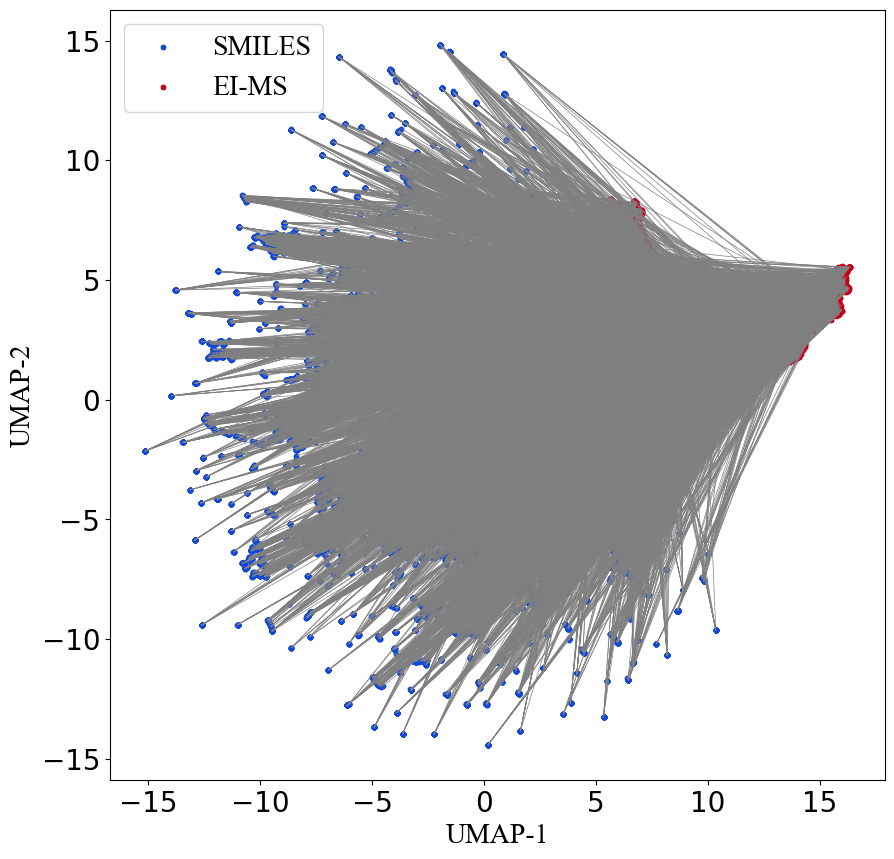

In [7]:
# use umap to reduce the dimension of the feature, and plot the 2D feature
import umap
import matplotlib.pyplot as plt
import numpy as np

reducer = umap.UMAP(n_components=2)
feature = np.concatenate([test_smiles_feature.cpu().numpy(), test_ms_feature.cpu().numpy()], axis=0)
len1 = test_smiles_feature.shape[0]
# print(feature.shape)
feature = reducer.fit_transform(feature)
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(feature[:len1, 0], feature[:len1, 1], color='#1147da', label='SMILES', s=10)
ax.scatter(feature[len1:, 0], feature[len1:, 1], color='#c6001b', label='EI-MS', s=10)

# Connect paired data points with lines
for i in range(len1):
    ax.plot([feature[i, 0], feature[len1 + i, 0]], [feature[i, 1], feature[len1 + i, 1]], color='gray', linestyle='-', linewidth=0.5)

ax.legend(prop={'family': 'times new roman', 'size': 20}, loc='upper left')
ax.set_ylabel('UMAP-2', fontsize=20, fontname='times new roman')
ax.set_xlabel('UMAP-1', fontsize=20, fontname='times new roman')
ax.tick_params(axis='both', which='major', labelsize=20)
# plt.savefig("fig/umap_epoch100.png", dpi=300)
plt.show()

d:\Anaconda\envs\csu-ei\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


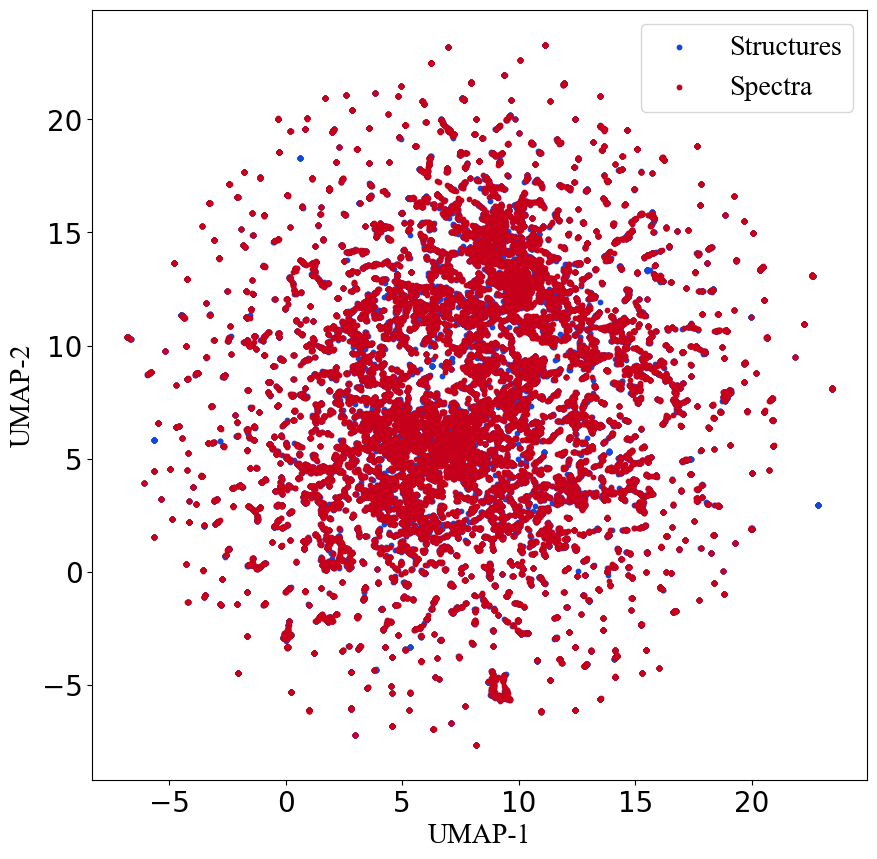

In [25]:
# use umap to reduce the dimension of the feature, and plot the 2D feature
import umap

reducer = umap.UMAP(n_components=2)
feature = np.concatenate([test_smiles_feature.cpu().numpy(), test_ms_feature.cpu().numpy()], axis=0)
len1 = test_smiles_feature.shape[0]
# print(feature.shape)
feature = reducer.fit_transform(feature)
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(feature[:len1, 0], feature[:len1, 1], color='#1147da', label='Structures', s=10)
ax.scatter(feature[len1:, 0], feature[len1:, 1], color='#c6001b', label='Spectra', s=10)
ax.legend(prop={'family': 'times new roman', 'size': 20}, loc='upper right')
ax.set_ylabel('UMAP-2', fontsize=20, fontname='times new roman')
ax.set_xlabel('UMAP-1', fontsize=20, fontname='times new roman')
ax.tick_params(axis='both', which='major', labelsize=20)
plt.savefig("d:/CSU-EI-paper/picture/性能评估与比较图/umap_epoch100.png", dpi=300)
plt.show()

(2000, 768)


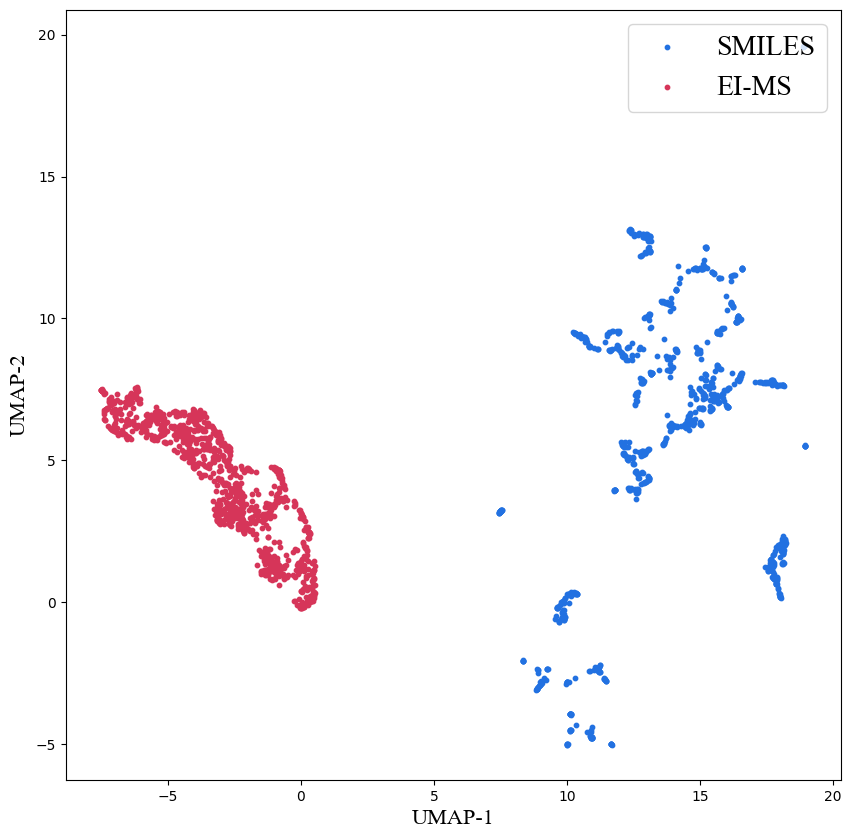

In [11]:
# use umap to reduce the dimension of the feature, and plot the 2D feature
import umap

reducer = umap.UMAP(n_components=2)
feature = np.concatenate([test_smiles_feature[:1000].cpu().numpy(), test_ms_feature[:1000].cpu().numpy()], axis=0)
print(feature.shape)
feature = reducer.fit_transform(feature)
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(feature[:1000, 0], feature[:1000, 1], color='#2271e1', label='SMILES', s=10)
ax.scatter(feature[1000:, 0], feature[1000:, 1], color='#d63559', label='EI-MS', s=10)
ax.legend(prop={'family': 'times new roman', 'size': 20
                }, loc='upper right')
ax.set_ylabel('UMAP-2', fontsize=16, fontname='times new roman')
ax.set_xlabel('UMAP-1', fontsize=16, fontname='times new roman')
# plt.savefig("fig/umap_epoch100.png", dpi=300)
plt.show()

In [19]:
import umap

reducer = umap.UMAP(n_components=3)
feature = np.concatenate([test_smiles_feature[:2000].cpu().numpy(), test_ms_feature[:2000].cpu().numpy()], axis=0)
feature = reducer.fit_transform(feature)
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(feature[:2000, 0], feature[:2000, 1], feature[:2000, 2], color='red', label='SMILES', s=1)
ax.scatter(feature[2000:, 0], feature[2000:, 1], feature[2000:, 2], color='blue', label='EI-MS', s=1)
ax.legend(fontsize=12, prop={'family': 'times new roman'}, loc='upper right') 

plt.show()

# 2、Cross-modal Retrieval between EI-MS and SMILES 

## SMIELS database(110 examples)

In [29]:
# example data "data/100_validations/100_val_smiles.csv"
# Load data
import pandas as pd
df = pd.read_csv("data/example_smiles_db/110_smiles.csv")
SMILES_110 = df["smiles"].values
smiles_ids_list = []
smiles_mask_list = []
for smiles in SMILES_110:
    smiles_ids, smiles_mask = pre_processing_smi(smiles,tokenizer,config_json)
    smiles_ids_list.append(smiles_ids)
    smiles_mask_list.append(smiles_mask)

smiles_ids = torch.cat(smiles_ids_list, dim=0).to(config_json["device"])
smiles_mask = torch.cat(smiles_mask_list, dim=0).to(config_json["device"])

In [ ]:
with torch.no_grad():
    model.eval()
    smiles_feature_db, smiles_score_db = model.smiles_encoder([smiles_ids, smiles_mask])
smiles_feature_db /= torch.norm(smiles_feature_db, dim=-1, keepdim=True) # 110 x 768

similarity_db = ms_feature @ smiles_feature_db.T  # 10 x 110
top_sim, top_smi = similarity_db.cpu().topk(5, dim=-1)
print(top_sim)
print(top_smi)

In [ ]:
from utils.plot_eims import plot_ms_spectrum
for i in range(10):
    plot_ms_spectrum(EIMS[i])
    print(f"Top5 SMILES for EI-MS {i+1}:")
    # for j in range(5):
    #     print(f"SMILES {j+1}: {SMILES_110[top_smi[i][j]]}, Similarity: {top_sim[i][j].item()}")
    

# 3、Visualization and Explainability

In [21]:
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib
# matplotlib.use('TkAgg')
from mpl_toolkits.axes_grid1 import make_axes_locatable

from model.CSU_EI import CSUEI
from model.tokenizer import build_tokenizer
from utils.data_preprocessing import pre_processing_ms, pre_processing_smi, get_tokenined_smiles

In [22]:
with open("configs/config.json", 'r') as f:
        config_json = json.loads(f.read())
model_dict = torch.load("model_weight/CSU_EI_weight/trained_model_6+6_16epoc+1024+3e4_2025-01-09_204745.pth", map_location=config_json["device"])
model = CSUEI(**config_json["model_config"])
model.load_state_dict(model_dict)
tokenizer = build_tokenizer(config_json['roberta_tokenizer_path'])

load pretrain smiles model


In [43]:
smiles = "BrCCCCCCCCCCCCOc1cc(Br)cc(Br)c1"
eims = "[[29.0, 0.1472], [30.0, 0.0025], [31.0, 0.0015], [32.0, 0.008100000000000001], [33.0, 0.0013], [37.0, 0.0021], [38.0, 0.0032], [39.0, 0.0617], [40.0, 0.0163], [41.0, 0.6378], [42.0, 0.0906], [43.0, 0.605], [44.0, 0.0231], [45.0, 0.0014000000000000002], [50.0, 0.0033], [51.0, 0.0043], [52.0, 0.0042], [53.0, 0.04190000000000001], [54.0, 0.0489], [55.0, 1.0], [56.0, 0.1527], [57.0, 0.5991], [58.0, 0.024300000000000002], [59.0, 0.0012], [61.0, 0.0024], [62.0, 0.0121], [63.0, 0.0605], [64.0, 0.011399999999999999], [65.0, 0.0121], [66.0, 0.0113], [67.0, 0.14400000000000002], [68.0, 0.0852], [69.0, 0.8974], [70.0, 0.1698], [71.0, 0.2891], [72.0, 0.0167], [73.0, 0.0039000000000000003], [74.0, 0.0126], [75.0, 0.0521], [76.0, 0.0073], [77.0, 0.010700000000000001], [78.0, 0.005], [79.0, 0.020499999999999997], [80.0, 0.0125], [81.0, 0.122], [82.0, 0.13390000000000002], [83.0, 0.5152], [84.0, 0.0873], [85.0, 0.1941], [86.0, 0.013999999999999999], [89.0, 0.0034000000000000002], [90.0, 0.0032], [91.0, 0.017], [92.0, 0.0055000000000000005], [93.0, 0.0085], [94.0, 0.005], [95.0, 0.0808], [96.0, 0.08439999999999999], [97.0, 0.6647], [98.0, 0.0676], [99.0, 0.0339], [100.0, 0.0034000000000000002], [103.0, 0.0042], [104.0, 0.0043], [105.0, 0.0121], [106.0, 0.0031], [107.0, 0.0229], [108.0, 0.0034999999999999996], [109.0, 0.0816], [110.0, 0.045599999999999995], [111.0, 0.3592], [112.0, 0.0429], [113.0, 0.005600000000000001], [115.0, 0.0018], [116.0, 0.0016], [117.0, 0.0058], [118.0, 0.0095], [119.0, 0.008100000000000001], [120.0, 0.0039000000000000003], [121.0, 0.0134], [122.0, 0.0014000000000000002], [123.0, 0.0745], [124.0, 0.031400000000000004], [125.0, 0.1493], [126.0, 0.0166], [127.0, 0.0022], [129.0, 0.0016], [131.0, 0.0058], [132.0, 0.0058], [133.0, 0.0074], [134.0, 0.0106], [135.0, 0.065], [136.0, 0.0098], [137.0, 0.0929], [138.0, 0.019], [139.0, 0.0098], [140.0, 0.0033], [141.0, 0.0029], [142.0, 0.003], [143.0, 0.0199], [144.0, 0.0055000000000000005], [145.0, 0.0192], [146.0, 0.0045000000000000005], [147.0, 0.006], [148.0, 0.18350000000000002], [149.0, 0.04190000000000001], [150.0, 0.177], [151.0, 0.036699999999999997], [152.0, 0.0022], [153.0, 0.0049], [154.0, 0.013999999999999999], [155.0, 0.0084], [156.0, 0.0349], [157.0, 0.006], [158.0, 0.02], [159.0, 0.0028000000000000004], [160.0, 0.0019], [161.0, 0.0063], [162.0, 0.0968], [163.0, 0.0215], [164.0, 0.0909], [165.0, 0.0203], [166.0, 0.012], [167.0, 0.013000000000000001], [168.0, 0.0028000000000000004], [169.0, 0.0024], [170.0, 0.0026], [171.0, 0.0172], [172.0, 0.0194], [173.0, 0.0168], [174.0, 0.0178], [175.0, 0.008199999999999999], [176.0, 0.0206], [177.0, 0.018000000000000002], [178.0, 0.019799999999999998], [179.0, 0.0106], [180.0, 0.0022], [183.0, 0.0019], [184.0, 0.006], [185.0, 0.0060999999999999995], [186.0, 0.0051], [187.0, 0.0052], [188.0, 0.0036], [189.0, 0.0069], [190.0, 0.0152], [191.0, 0.0141], [192.0, 0.013000000000000001], [193.0, 0.0104], [194.0, 0.0012], [195.0, 0.0011], [197.0, 0.0023], [198.0, 0.0016], [199.0, 0.0027], [200.0, 0.0014000000000000002], [201.0, 0.0015], [202.0, 0.0031], [203.0, 0.0104], [204.0, 0.008], [205.0, 0.013600000000000001], [206.0, 0.0072], [207.0, 0.0123], [208.0, 0.0025], [209.0, 0.0026], [211.0, 0.0045000000000000005], [212.0, 0.0022], [213.0, 0.0036], [216.0, 0.0012], [217.0, 0.004699999999999999], [218.0, 0.0088], [219.0, 0.0053], [220.0, 0.0074], [221.0, 0.0042], [222.0, 0.0025], [223.0, 0.0072], [224.0, 0.0043], [225.0, 0.004], [226.0, 0.0024], [227.0, 0.0022], [228.0, 0.0017000000000000001], [229.0, 0.0014000000000000002], [233.0, 0.0144], [234.0, 0.0021], [235.0, 0.0248], [236.0, 0.0028000000000000004], [237.0, 0.0144], [238.0, 0.0025], [239.0, 0.0024], [240.0, 0.0011], [241.0, 0.0013], [246.0, 0.013600000000000001], [247.0, 0.003], [248.0, 0.013300000000000001], [249.0, 0.0037], [250.0, 0.34119999999999995], [251.0, 0.0401], [252.0, 0.6261], [253.0, 0.0695], [254.0, 0.3079], [255.0, 0.031400000000000004], [256.0, 0.0031], [257.0, 0.0016], [259.0, 0.0013], [263.0, 0.009399999999999999], [264.0, 0.0017000000000000001], [265.0, 0.0134], [266.0, 0.0017000000000000001], [267.0, 0.0091], [268.0, 0.0017000000000000001], [269.0, 0.0011], [273.0, 0.0012], [276.0, 0.0024], [278.0, 0.0024], [279.0, 0.0011], [280.0, 0.0014000000000000002], [281.0, 0.0034000000000000002], [282.0, 0.0018], [283.0, 0.0025], [286.0, 0.0019], [289.0, 0.0013], [291.0, 0.0014000000000000002], [293.0, 0.0015], [294.0, 0.0013], [297.0, 0.0016], [299.0, 0.0013], [314.0, 0.0011], [315.0, 0.0016], [324.0, 0.0011], [331.0, 0.0012], [335.0, 0.0014000000000000002], [337.0, 0.0039000000000000003], [338.0, 0.0025], [339.0, 0.0049], [340.0, 0.0033], [341.0, 0.0012], [351.0, 0.0013], [354.0, 0.0011], [356.0, 0.0014000000000000002], [365.0, 0.0012], [367.0, 0.0017000000000000001], [369.0, 0.0011], [371.0, 0.0011], [376.0, 0.0016], [388.0, 0.0012], [389.0, 0.0013], [392.0, 0.0011], [394.0, 0.0013], [401.0, 0.0019], [406.0, 0.0012], [411.0, 0.0011], [413.0, 0.0011], [417.0, 0.008100000000000001], [418.0, 0.0018], [419.0, 0.0182], [420.0, 0.0043], [421.0, 0.0091], [422.0, 0.0028000000000000004], [428.0, 0.0014000000000000002], [429.0, 0.0015], [431.0, 0.0012], [435.0, 0.0011], [439.0, 0.0016], [454.0, 0.0014000000000000002], [459.0, 0.0011], [463.0, 0.0016], [464.0, 0.0011], [470.0, 0.0011], [474.0, 0.0013], [476.0, 0.0011], [483.0, 0.0016], [496.0, 0.0305], [497.0, 0.0066], [498.0, 0.0867], [499.0, 0.018600000000000002], [500.0, 0.087], [501.0, 0.018000000000000002], [502.0, 0.0276], [503.0, 0.0062], [510.0, 0.0014000000000000002], [511.0, 0.0012], [526.0, 0.002], [531.0, 0.0014000000000000002], [536.0, 0.0015], [538.0, 0.0011], [541.0, 0.0012], [547.0, 0.0012], [552.0, 0.0012], [559.0, 0.0011], [560.0, 0.0015], [574.0, 0.0015], [577.0, 0.0011], [584.0, 0.0017000000000000001], [586.0, 0.0012], [592.0, 0.0013], [593.0, 0.0013], [603.0, 0.0011], [606.0, 0.0019], [608.0, 0.0016], [611.0, 0.0011], [613.0, 0.0018], [625.0, 0.0011], [636.0, 0.0011], [639.0, 0.0012], [644.0, 0.0011], [645.0, 0.0019], [655.0, 0.0015], [656.0, 0.0013], [664.0, 0.0019], [670.0, 0.0015], [675.0, 0.0014000000000000002], [679.0, 0.0016], [680.0, 0.0013], [683.0, 0.0014000000000000002], [684.0, 0.0014000000000000002], [689.0, 0.0012], [698.0, 0.0013], [701.0, 0.0012], [712.0, 0.0014000000000000002], [716.0, 0.0012], [717.0, 0.0011], [718.0, 0.0012], [721.0, 0.0011], [722.0, 0.0012], [727.0, 0.0017000000000000001], [728.0, 0.0015], [733.0, 0.0013], [742.0, 0.0017000000000000001], [747.0, 0.0014000000000000002], [749.0, 0.0012], [750.0, 0.0012], [766.0, 0.0012], [774.0, 0.0017000000000000001], [779.0, 0.0016], [783.0, 0.0011], [788.0, 0.0012], [789.0, 0.0016], [793.0, 0.0015], [794.0, 0.0015], [799.0, 0.0011], [800.0, 0.0011]]"

# with open('data/explain_data/ethyl_alcohol.json', 'r') as f:
# with open('data/xianglansu/smiles_ms.json', 'r') as f:
#     data = json.load(f)
# smiles = data[0]['smiles']
# eims = data[0]['peaks']
df = pd.read_csv("data/extra_10_test/10.csv")
smiles = df["smiles"].values[3]
eims = df["spectra"].values[3]
smiles_ids, smiles_mask = pre_processing_smi(smiles,tokenizer,config_json)
mz, intensity, ms_mask = pre_processing_ms(eims,config_json)
with torch.no_grad():
    model.eval()
    smiles_feature, smiles_score = model.smiles_encoder([smiles_ids, smiles_mask])
    ms_feature, ms_score = model.ms_encoder([mz, intensity, ms_mask])

mz = mz.squeeze(0).cpu().detach().numpy()[ms_mask.squeeze(0) == 1]
mz = mz.astype(int)
smiles_token = get_tokenined_smiles(smiles, tokenizer, config_json)
smiles_feature /= torch.norm(smiles_feature, dim=-1, keepdim=True)
ms_feature /= torch.norm(ms_feature, dim=-1, keepdim=True)
similarity = smiles_feature.cpu().numpy() @ ms_feature.cpu().numpy().T
print(similarity)

[[0.97545946]]


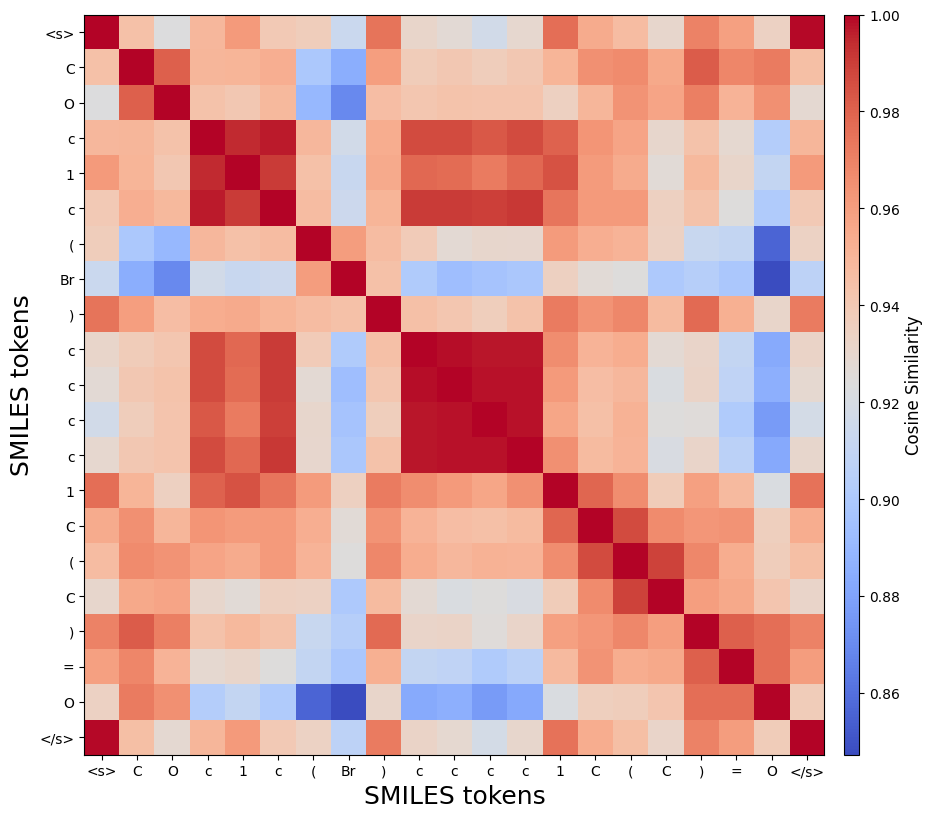

In [44]:
#  SMILES tokens and SMILES tokens cosine similarity
smi_esa_score = smiles_score[smiles_mask == 1]
smi_esa_score /= torch.norm(smi_esa_score, dim=1, keepdim=True)
token_peak_cos_similarity = smi_esa_score.cpu().numpy() @ smi_esa_score.cpu().numpy().T

plt.figure(figsize=(10, 10))

plt.xticks(range(len(smiles_token)), smiles_token, fontsize=10)
plt.yticks(range(len(smiles_token)), smiles_token, fontsize=10)
# 设置坐标轴标签
plt.xlabel('SMILES tokens', fontsize=18)
plt.ylabel('SMILES tokens', fontsize=18)
# 创建 colorbar 并使其与热力图等高
ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)


# 保存热力图
# plt.savefig('fig/10_esa_smiles_smiles_heatmap_score_l2norm.png', dpi=300)
plt.show()

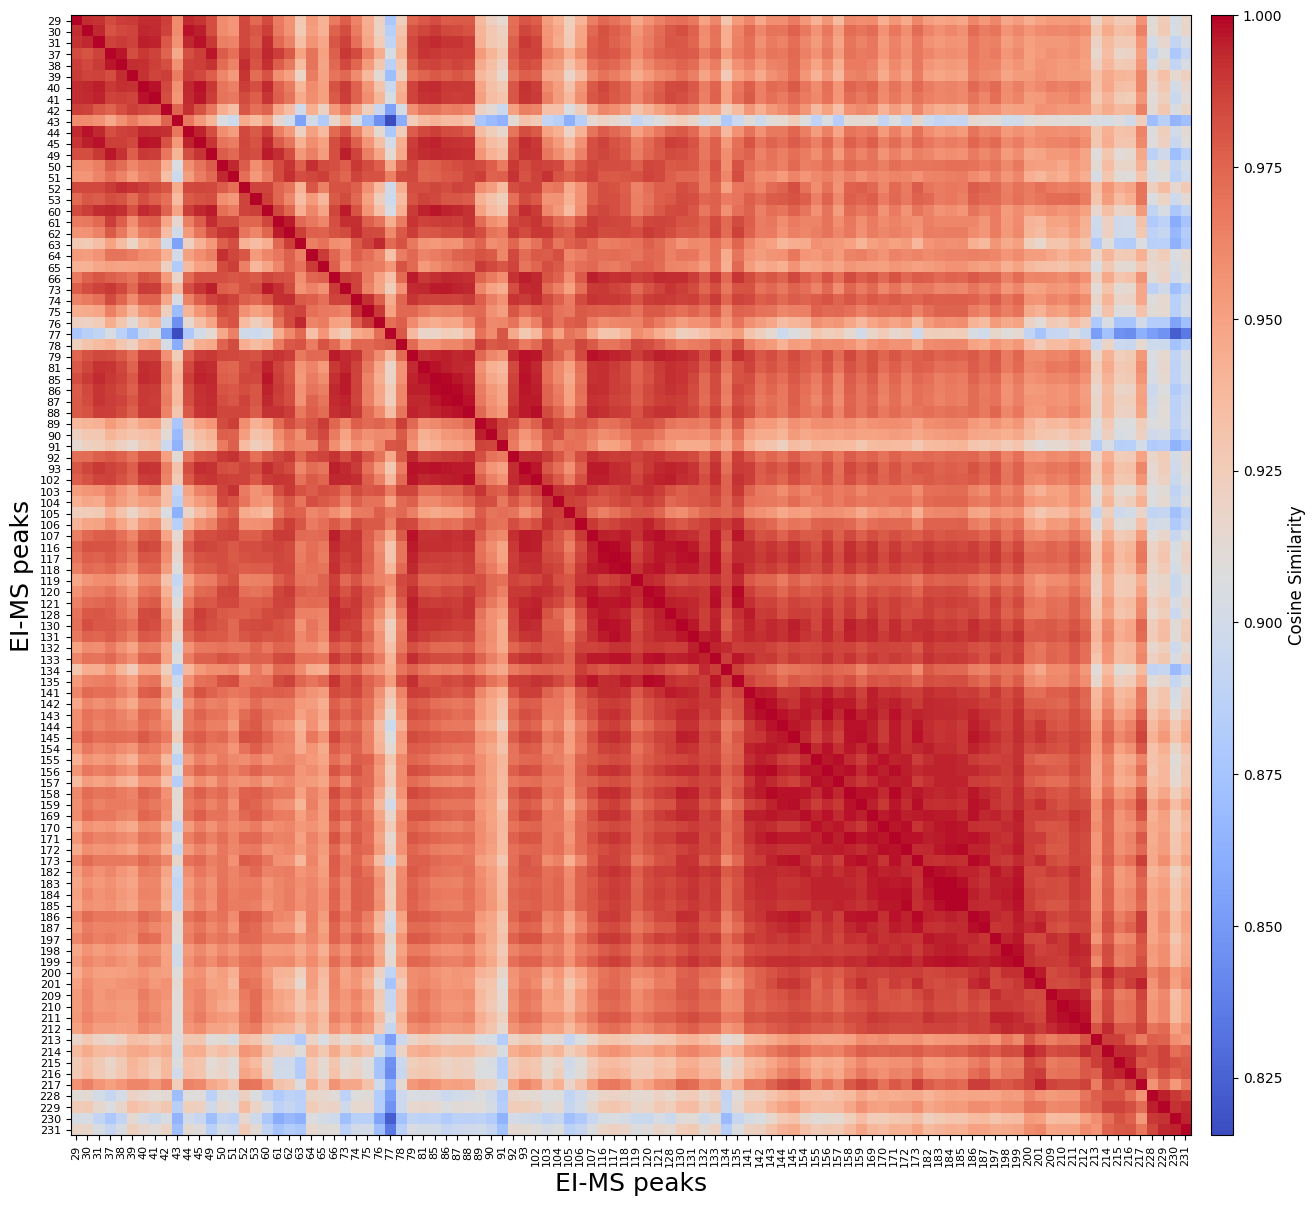

In [45]:
# EI-MS tokens and EI-MS tokens cosine similarity
ms_esa_score = ms_score[ms_mask == 1]
ms_esa_score /= torch.norm(ms_esa_score, dim=1, keepdim=True)
token_peak_cos_similarity = ms_esa_score.cpu().numpy() @ ms_esa_score.cpu().numpy().T


plt.figure(figsize=(15, 15))

plt.xticks(range(len(mz)), mz, fontsize=8, rotation=90)
plt.yticks(range(len(mz)), mz, fontsize=8)

plt.xlabel('EI-MS peaks', fontsize=18)
plt.ylabel('EI-MS peaks', fontsize=18)

ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

# plt.savefig('fig/10_esa_ms_ms_heatmap_score_l2norm.png', dpi=300)
plt.show()

[[0.94268817 0.9640206  0.9309664  0.9422469  0.9182814  0.93546414]]


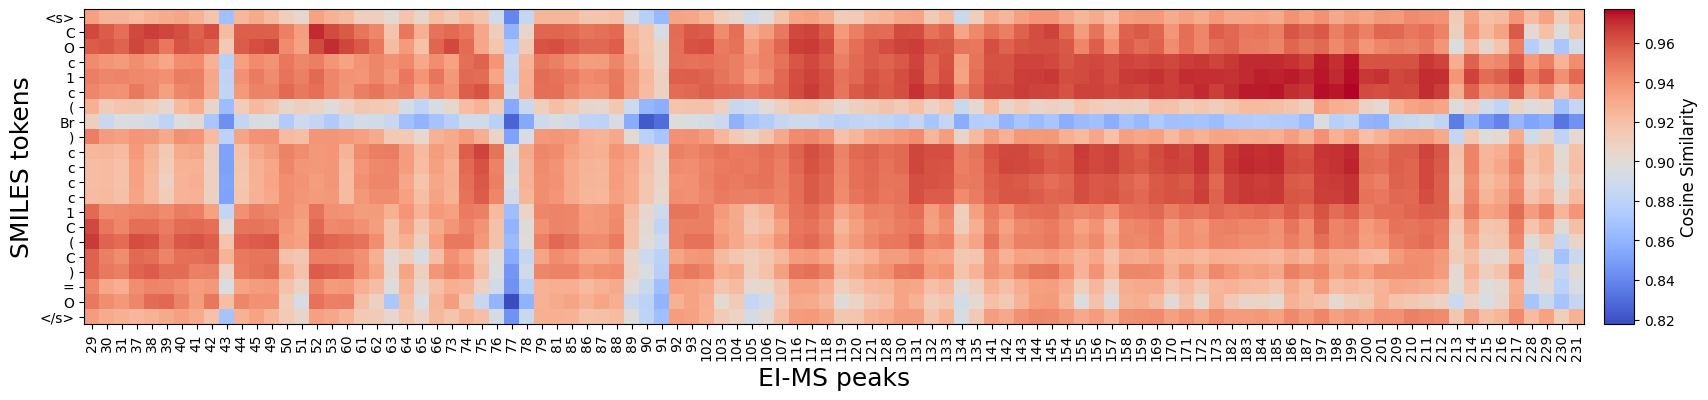

In [46]:
# SMILES tokens and EI-MS peaks cosine similarity

# smiles_ids, smiles_mask = pre_processing_smi(smiles,tokenizer,config_json)
# mz, intensity, ms_mask = pre_processing_ms(eims,config_json)
# with torch.no_grad():
#     model.eval()
#     smiles_feature, smiles_score = model.smiles_encoder([smiles_ids, smiles_mask])
#     ms_feature, ms_score = model.ms_encoder([mz, intensity, ms_mask])

smi_esa_score = smiles_score[smiles_mask == 1]
ms_esa_score = ms_score[ms_mask == 1]
smi_esa_score /= torch.norm(smi_esa_score, dim=1, keepdim=True)
ms_esa_score /= torch.norm(ms_esa_score, dim=1, keepdim=True)
smiles_feature /= torch.norm(smiles_feature, dim=1, keepdim=True)
token_peak_cos_similarity = smi_esa_score.cpu().numpy() @ ms_esa_score.cpu().numpy().T

max_peak_molecule_similarity =  smiles_feature.cpu().numpy() @ ms_esa_score[-6:].cpu().numpy().T
print(max_peak_molecule_similarity)

smiles_token = get_tokenined_smiles(smiles, tokenizer, config_json)

plt.figure(figsize=(20, 20))

# plt.imshow(token_peak_cos_similarity, cmap='GnBu', interpolation='nearest') 
# plt.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest') 

plt.xticks(range(len(mz)), mz, fontsize=10, rotation=90)
plt.yticks(range(len(smiles_token)), smiles_token, fontsize=10)
# 设置坐标轴标签
plt.xlabel('EI-MS peaks', fontsize=18)
plt.ylabel('SMILES tokens', fontsize=18)
# 创建 colorbar 并使其与热力图等高
ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

# plt.savefig('fig/10_esa_smiles_ms_heatmap_score_l2norm.png', dpi=300)
plt.show()

# 4、Molecular localization in GC-MS files

In [70]:
from utils.NetCDF import netcdf_reader, get_mass_data_from_cdf, data_load
from data_provider.dataset import pre_processing_ms, pre_processing_smi, process_ms_spectra_for_wcs, get_cos_distance
import torch
import matplotlib.pyplot as plt
import numpy as np  
import pandas as pd
import json

# 假设 CDF 文件的路径为 'data.cdf'
filename = 'data/xianglansu/250106-奶粉-香兰素.CDF'
# filename = 'data/set1/1.0.CDF'
# 读取 CDF 文件中的数据
X, mz, rt = data_load(filename)
print('intensity:')
print(X)
print('mz:')
print(mz)
# 检查X中为nan的数据
# nan_idx = np.argwhere(np.isnan(X))
# print('nan:', nan_idx)
# print(X.shape) # (5700, 1000)
num_ms, num_mz = X.shape
print(rt)
print(rt.shape) # (5700,)
mz = np.tile(mz, (num_ms, 1))
print(mz.shape)
print(mz)
# concat mz and X, to 5700 x 1000 x 2
set1_mass_data = np.dstack((mz, X))
nan_idx = np.argwhere(np.isnan(set1_mass_data))
print('nan:', nan_idx)
print(set1_mass_data.shape)
print(set1_mass_data[0])
# set1_reader = netcdf_reader(filename)
# rt = set1_reader.scan_acquisition_time.data
# print(rt)
# print(rt.shape)


intensity:
[[ 2.7086e+04  2.6495e+04  2.6209e+04 ...  4.3800e+02  3.5100e+02
   3.9900e+02]
 [ 9.9350e+03  9.9780e+03  1.0091e+04 ...  1.5100e+02  1.4000e+02
   1.6200e+02]
 [ 1.8600e+02  1.1100e+02  7.3000e+01 ...  4.2000e+01  5.4000e+01
   6.0000e+01]
 ...
 [ 1.4200e+02  4.6000e+01  5.7000e+01 ...  2.9000e+01  4.7000e+01
   1.6000e+01]
 [ 1.2100e+02  9.2000e+01  3.9000e+01 ... -1.1000e+01  3.3000e+01
   5.0000e+00]
 [ 3.5400e+02  6.3000e+01  2.2000e+01 ... -3.7000e+01  2.2000e+01
   5.0000e+00]]
mz:
[ 29  30  31  32  33  34  35  36  37  38  39  40  41  42  43  44  45  46
  47  48  49  50  51  52  53  54  55  56  57  58  59  60  61  62  63  64
  65  66  67  68  69  70  71  72  73  74  75  76  77  78  79  80  81  82
  83  84  85  86  87  88  89  90  91  92  93  94  95  96  97  98  99 100
 101 102 103 104 105 106 107 108 109 110 111 112 113 114 115 116 117 118
 119 120 121 122 123 124 125 126 127 128 129 130 131 132 133 134 135 136
 137 138 139 140 141 142 143 144 145 146 147 148 149 15

C:\Users\longjia\AppData\Local\Temp\ipykernel_3412\1920755102.py:13: RuntimeWarning: Cannot close a netcdf_file opened with mmap=True, when netcdf_variables or arrays referring to its data still exist. All data arrays obtained from such files refer directly to data on disk, and must be copied before the file can be cleanly closed. (See netcdf_file docstring for more information on mmap.)
  X, mz, rt = data_load(filename)


In [71]:
# load SMILES and EI-MS data from NIST23 dataset
with open("data/xianglansu/smiles_ms.json", 'r') as f:
# with open("data/set1/smiles_ms.json", 'r') as f:

    nist_23data = json.loads(f.read())
smiles_list = []
nist_ms_list = []
for data in nist_23data:
    nist_ms_list.append(data["peaks"])
    smiles_list.append(data["smiles"])

# with open("data/xianglansu/xls_smiles.txt", 'r') as f:
# with open("data/set1/smiles_list.txt", 'r') as f:
#     for line in f:
#         smiles_list.append(line.strip())
# save to csv file
# df = pd.DataFrame({"smiles": smiles_list, "spectra": nist_ms_list})
# df.to_csv("data/xianglansu/smiles_ms.csv", index=False)
# save smiles in txt file
# with open("data/set1/smiles_list.txt", 'w') as f:
#     for smiles in smiles_list:
#         f.write(smiles + '\n')

In [72]:
# load SMILES and EI-MS data from csv file
# df = pd.read_csv("data/xianglansu/smiles_ms.csv")
# nist_ms_list = df["spectra"].values
# smiles_list = df["smiles"].values

## 4.1 EI-MS WCS match

In [73]:
nist_ms_tensor = torch.cat([process_ms_spectra_for_wcs(nist_ms, 1000) for nist_ms in nist_ms_list], dim=0).reshape(-1, 1000)
nan_idx = torch.argwhere(torch.isnan(nist_ms_tensor))
print('nan:', nan_idx)
print(nist_ms_tensor.shape)
set1_ms_tensor = torch.cat([process_ms_spectra_for_wcs(set1_ms, 1000) for set1_ms in set1_mass_data], dim=0).reshape(-1, 1000)
nan_idx = torch.argwhere(torch.isnan(set1_ms_tensor))
print('nan:', nan_idx)
print(set1_ms_tensor.shape)

nan: tensor([], size=(0, 2), dtype=torch.int64)
torch.Size([3, 1000])
nan: tensor([], size=(0, 2), dtype=torch.int64)
torch.Size([8400, 1000])


(3, 8400)
[0.8946875  0.32496515 0.22516814]
14.2433(0.8947)
14.2433(0.3250)
14.2433(0.2252)


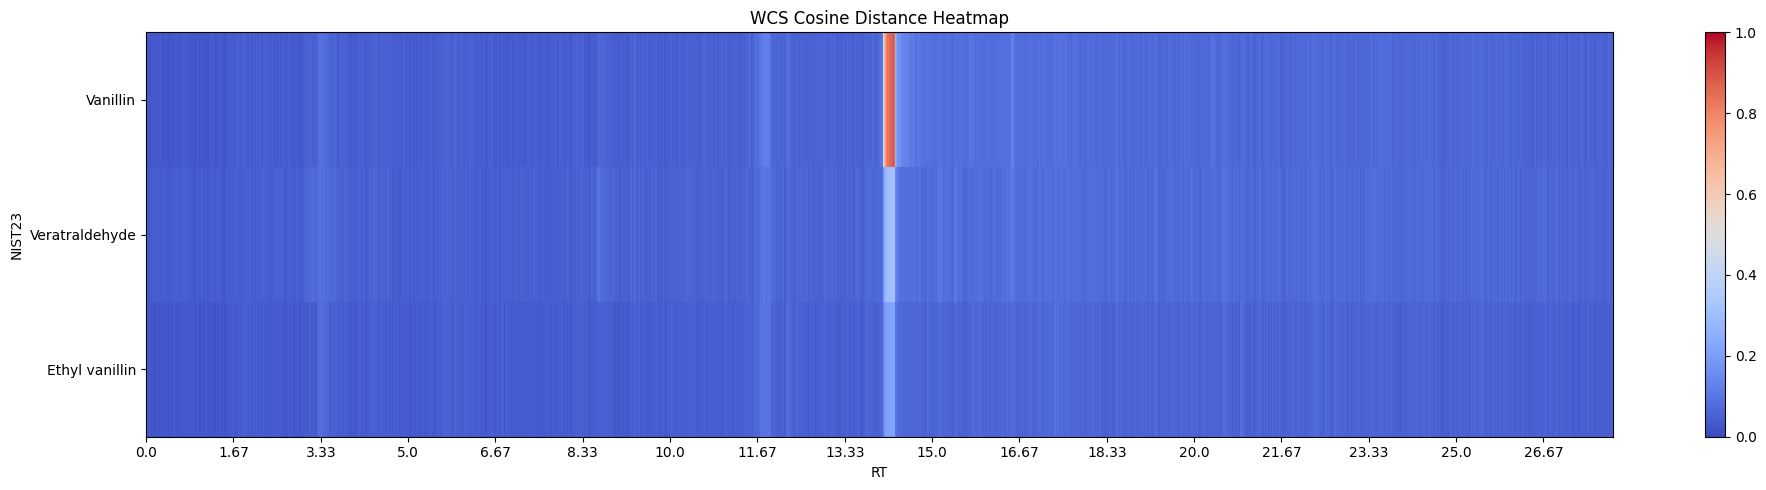

In [74]:
nist_ms_tensor /= torch.norm(nist_ms_tensor, dim=-1, keepdim=True)
set1_ms_tensor /= torch.norm(set1_ms_tensor, dim=-1, keepdim=True)
wcs_similarity = nist_ms_tensor @ set1_ms_tensor.T
# nan to 0
wcs_similarity[torch.isnan(wcs_similarity)] = 0
wcs_similarity = wcs_similarity.cpu().numpy()
print(wcs_similarity.shape)

# 打印出每行的最大值，以及最大值所在的列索引，再拿到对应的 RT
max_distance = wcs_similarity.max(axis=1)
print(max_distance)
rt_list = rt[wcs_similarity.argmax(axis=1).tolist()]

result = np.concatenate([np.round(rt_list, 4).reshape(-1, 1), np.round(max_distance, 4).reshape(-1, 1)], axis=1)

for i in range(len(result)):

    print(f"{result[i][0]:.4f}({result[i][1]:.4f})")

name = ['Vanillin', 'Veratraldehyde', 'Ethyl vanillin']
# name = ['Vanillin']

# 绘制热力图
plt.figure(figsize=(20, 5))  # 调整图像大小
plt.imshow(wcs_similarity, aspect='auto', cmap='coolwarm', interpolation='nearest', norm=Normalize(vmin=0, vmax=1))
plt.colorbar()
plt.title('WCS Cosine Distance Heatmap')
plt.xlabel('RT')
plt.ylabel('NIST23')

# 设置 x 轴的范围和刻度
plt.xticks(ticks=np.arange(0, len(rt), step=500), labels=np.round(rt[np.arange(0, len(rt), step=500)], 2))
plt.yticks(ticks=np.arange(0, len(nist_ms_list), step=1), labels=name)
plt.tight_layout()
# plt.savefig("fig/location/wcs_similarity_heatmap.png", bbox_inches='tight')
plt.show()


## 4.1 cross modal location

In [75]:
smiles_ids_list = []
smiles_mask_list = []
for smiles in smiles_list:
    smiles_ids, smiles_mask = pre_processing_smi(smiles,tokenizer,config_json)
    smiles_ids_list.append(smiles_ids)
    smiles_mask_list.append(smiles_mask)

smiles_ids = torch.cat(smiles_ids_list, dim=0).to(config_json["device"])
smiles_mask = torch.cat(smiles_mask_list, dim=0).to(config_json["device"])

with torch.no_grad():
    model.eval()
    set1_smiles_feature, set1_smiles_score = model.smiles_encoder([smiles_ids, smiles_mask])


In [76]:
from tqdm import tqdm

mz_list = []
intensity_list = []
ms_mask_list = []


for i in tqdm(range(len(set1_mass_data))):
    mz, intensity, ms_mask = pre_processing_ms(set1_mass_data[i].tolist(),config_json)
    mz_list.append(mz)
    intensity_list.append(intensity)
    ms_mask_list.append(ms_mask)
                                                    
mz = torch.cat(mz_list, dim=0).to(config_json["device"])
intensity = torch.cat(intensity_list, dim=0).to(config_json["device"])
ms_mask = torch.cat(ms_mask_list, dim=0).to(config_json["device"])

print(mz.shape)

batch_size = 100
set1_ms_feature = []
with torch.no_grad():
    for i in range(0, len(mz), batch_size):
        model.to(config_json["device"])
        model.eval()
        # 获取当前批次的数据
        ms_feature, ms_score = model.ms_encoder([mz[i:i+batch_size], intensity[i:i+batch_size], ms_mask[i:i+batch_size]])
        set1_ms_feature.append(ms_feature)

set1_ms_feature = torch.cat(set1_ms_feature, dim=0)


100%|██████████| 8400/8400 [00:02<00:00, 3939.52it/s]


torch.Size([8400, 100])


14.2767(0.9749)
14.2767(0.7127)
14.2767(0.7401)


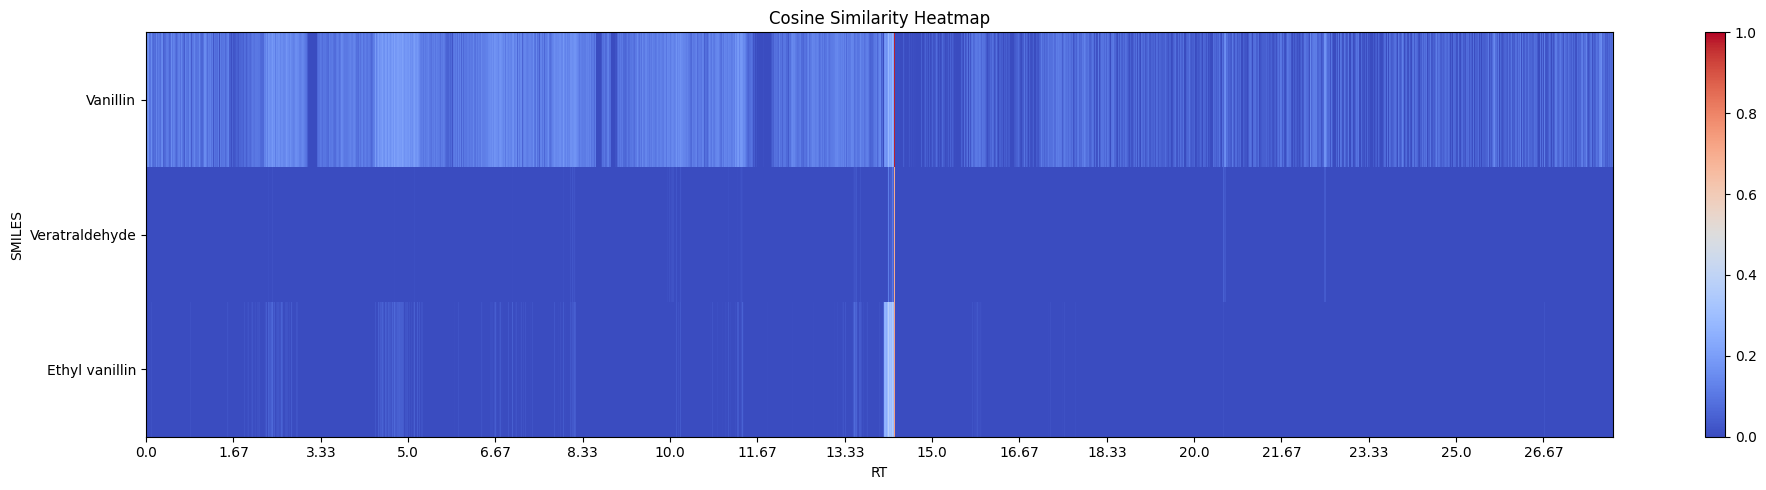

In [77]:
set1_smiles_feature /= torch.norm(set1_smiles_feature, dim=-1, keepdim=True)

set1_ms_feature /= torch.norm(set1_ms_feature, dim=-1, keepdim=True)
cross_modal_similarity = set1_smiles_feature.cpu().numpy() @ set1_ms_feature.cpu().numpy().T
# nan to 0
cross_modal_similarity[np.isnan(cross_modal_similarity)] = 0
# 打印出每行的最大值，以及最大值所在的列索引，再拿到对应的 RT
max_distance = cross_modal_similarity.max(axis=1)
rt_list = rt[cross_modal_similarity.argmax(axis=1).tolist()]

result = np.concatenate([np.round(rt_list, 4).reshape(-1, 1), np.round(max_distance, 4).reshape(-1, 1)], axis=1)

for i in range(len(result)):
    print(f"{result[i][0]:.4f}({result[i][1]:.4f})")

name = ['Vanillin']
name = ['Vanillin', 'Veratraldehyde', 'Ethyl vanillin']

# 绘制热力图
plt.figure(figsize=(20, 5))  # 调整图像大小
plt.imshow(cross_modal_similarity, aspect='auto', cmap='coolwarm', interpolation='nearest', norm=Normalize(vmin=0, vmax=1))
plt.colorbar()
plt.title('Cosine Similarity Heatmap')
plt.xlabel('RT')
plt.ylabel('SMILES')

# 设置 x 轴的范围和刻度
plt.xticks(ticks=np.arange(0, len(rt), step=500), labels=np.round(rt[np.arange(0, len(rt), step=500)], 2))
plt.yticks(ticks=np.arange(0, len(smiles_list), step=1), labels=name)

# 调整布局以确保完整显示
plt.tight_layout()
# plt.savefig("fig/location/set1_0.8/cross_modal_similarity_heatmap.png", bbox_inches='tight')
plt.show()


In [61]:
# 画出smiles_list中的smiles的分子结构
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem

mol_list = [Chem.MolFromSmiles(smiles) for smiles in smiles_list]
for i in range(len(mol_list)):
    mol = mol_list[i]
    AllChem.Compute2DCoords(mol)
    img = Draw.MolToImage(mol, size=(300, 300))
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f'SMILES {i+1}', fontsize=12)
    plt.savefig(f"fig/location/SMILES_PIC/SMILES_{i+1}.png", bbox_inches='tight')
    plt.close()